# 04 · Clustering

**Goal.** Group countries with similar data and check how solid the groups are.

* Countries are clustered on their scores on the components retained by parallel analysis (at least 2), which removes the noise directions.
* **Ward hierarchical clustering** is the main method: the dendrogram shows the structure at every level.
  **k-means** is run alongside; the Adjusted Rand Index (ARI) measures their agreement (1 = same groups).
* **Choosing k** (2–6): the default is the highest Ward silhouette among solutions with no single-country cluster.
  The **gap statistic** is also shown *including k = 1*: if k = 1 wins, the data do not support clusters at all.
* **Stability:** countries are resampled with replacement 1,000 times and re-clustered.
  Per cluster, the mean Jaccard similarity with its best match (> 0.75 stable, 0.6–0.75 a pattern, < 0.5 dissolves).
  Per country, how often it stays with the other members of its cluster.
* **Cluster profiles** show the mean z-score per subdimension, which is what gives each group a meaning.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

from ilia_explore import data as D, pruning as P, pca as PC, clustering as CL, plots as PL, pipeline as PP

PL.setup_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.precision", 3)

In [2]:
codebook = D.load_codebook()
runs = {}
for cfg in PP.CONFIGS:
    for mode in PP.MODES:
        r = PP.run(cfg, mode)
        PP.save(r)
        runs[(cfg, mode)] = r

summary = pd.DataFrame({
    f"{c} · {m}": {
        "PCs used": r.k_pc, "k chosen": r.k, "k by gap rule": CL.gap_k(r.evaluation),
        "silhouette (Ward)": r.silhouette.mean(),
        "ARI Ward vs k-means": CL.adjusted_rand_score(r.ward, r.kmeans),
        "min cluster Jaccard": r.jaccard.min(), "mean cluster Jaccard": r.jaccard.mean(),
        "cluster sizes": "/".join(str(int(n)) for n in pd.Series(r.ward).value_counts().sort_index()),
    } for (c, m), r in runs.items()}).T
summary.to_csv(D.RESULTS / "clustering_overview.csv")
summary

,PCs used,k chosen,k by gap rule,silhouette (Ward),ARI Ward vs k-means,min cluster Jaccard,mean cluster Jaccard,cluster sizes
A-full · level,2,4,2,0.526,0.893,0.669,0.831,8/6/3/3
A-full · profile,4,2,1,0.241,0.8,0.622,0.662,11/9
A-pruned · level,2,2,2,0.517,1.0,0.951,0.952,10/10
A-pruned · profile,3,2,1,0.53,1.0,0.782,0.812,19/1
I-full · level,2,2,2,0.511,0.8,0.902,0.908,11/9
I-full · profile,4,2,1,0.205,0.8,0.614,0.616,11/9
I-pruned · level,2,2,1,0.487,0.62,0.86,0.864,11/9
I-pruned · profile,4,2,1,0.194,1.0,0.548,0.573,11/9


In [3]:
membership = pd.DataFrame({f"{c} · {m}": r.ward for (c, m), r in runs.items()},
                          index=D.iso(runs[("A-full", "level")].X.index))
membership.to_csv(D.RESULTS / "cluster_membership_all_runs.csv")
membership

,A-full · level,A-full · profile,A-pruned · level,A-pruned · profile,I-full · level,I-full · profile,I-pruned · level,I-pruned · profile
ARG,2,2,1,1,2,1,1,2
BOL,1,1,2,1,1,2,2,1
BRA,3,2,1,1,2,1,1,2
CHL,3,1,1,1,2,1,1,2
COL,2,2,1,1,2,1,1,2
CRI,2,2,1,1,2,1,1,1
CUB,4,2,2,2,1,1,2,1
ECU,2,2,1,1,2,1,1,2
SLV,4,2,2,1,1,1,2,1
GTM,1,1,2,1,1,2,2,1


## Level view


### A-full · level: k = 4 on 2 PCs
   silhouette_ward  silhouette_kmeans  ari_ward_vs_kmeans  min_cluster_size_ward    gap  gap_se  tibshirani_ok
k                                                                                                             
1              NaN                NaN                 NaN                    NaN  0.051   0.168          False
2            0.496              0.536               0.800                    9.0  0.280   0.170           True
3            0.506              0.552               0.876                    3.0  0.213   0.185          False
4            0.526              0.563               0.893                    3.0  0.414   0.197           True
5            0.484              0.506               0.635                    1.0  0.427   0.210           True
6            0.459              0.455               0.780                    1.0  0.428   0.221           True
cluster stability (mean Jaccard): {1: 0.91, 2: 0.83, 3: 0.92, 4: 0.67}


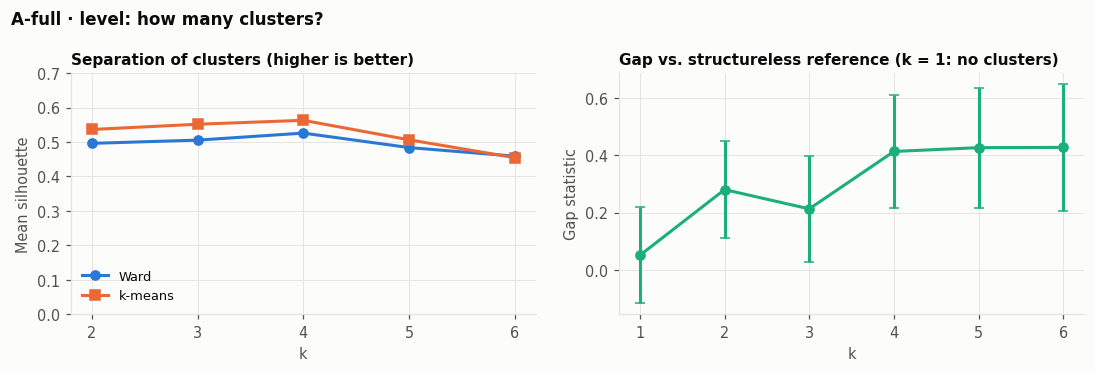

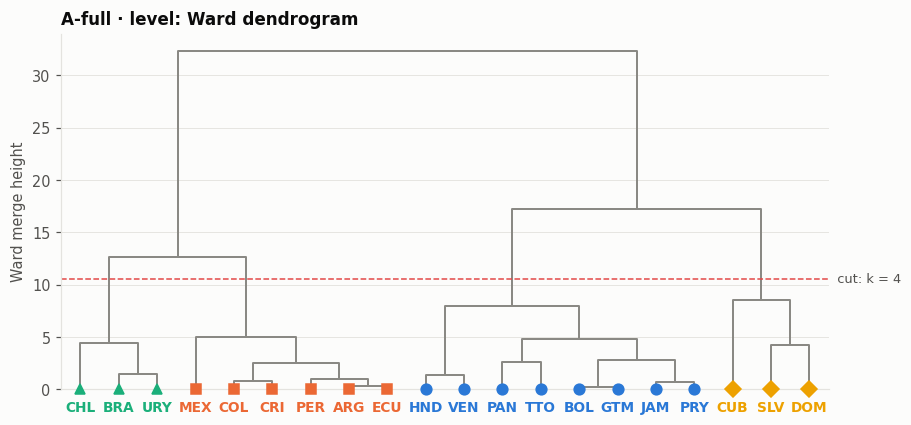

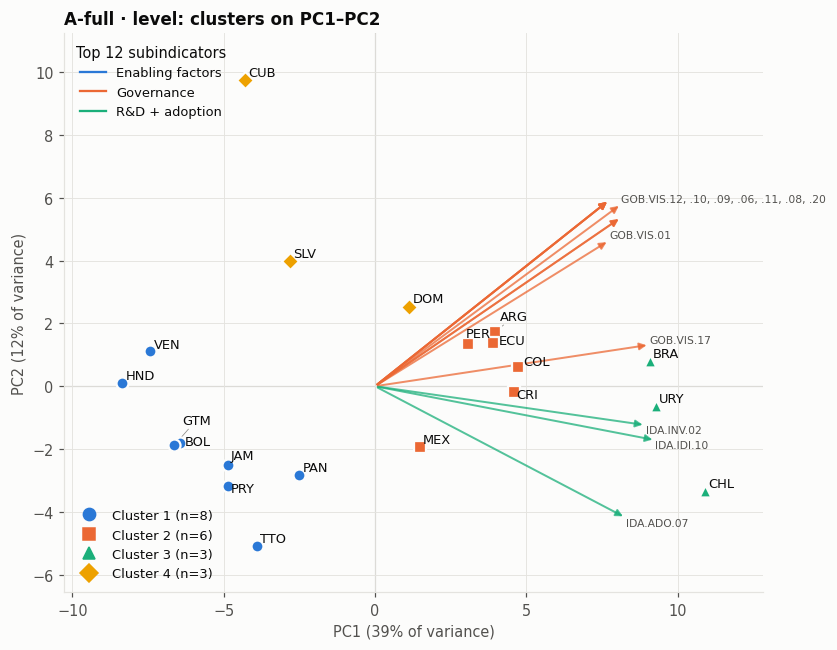

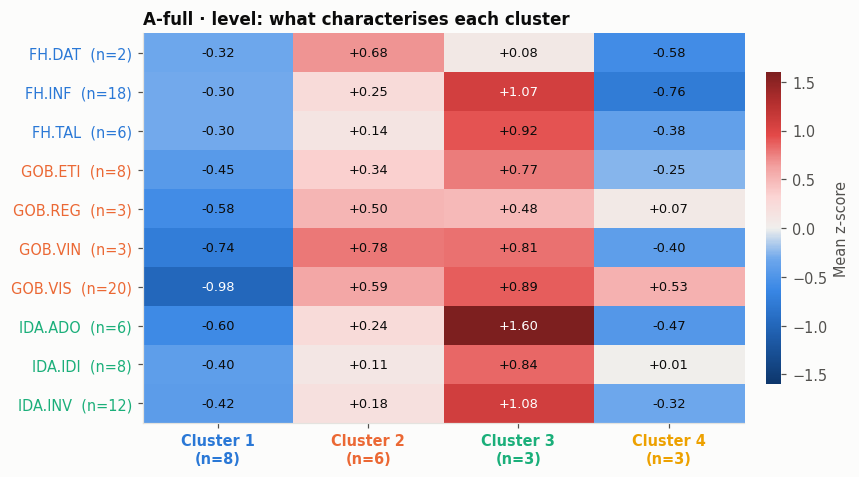

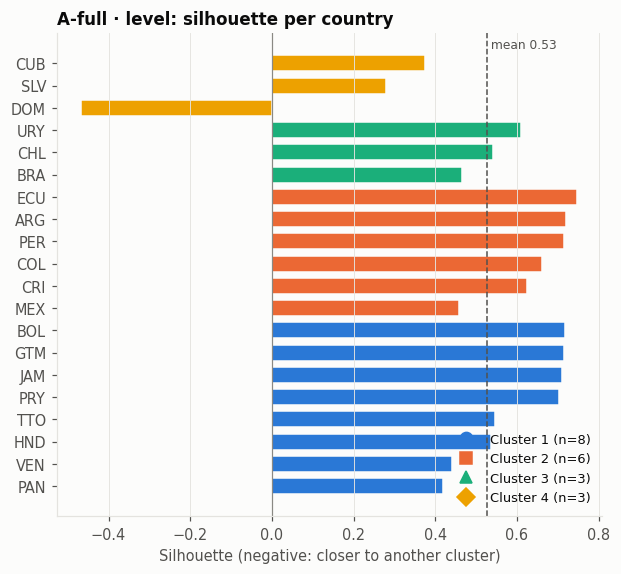

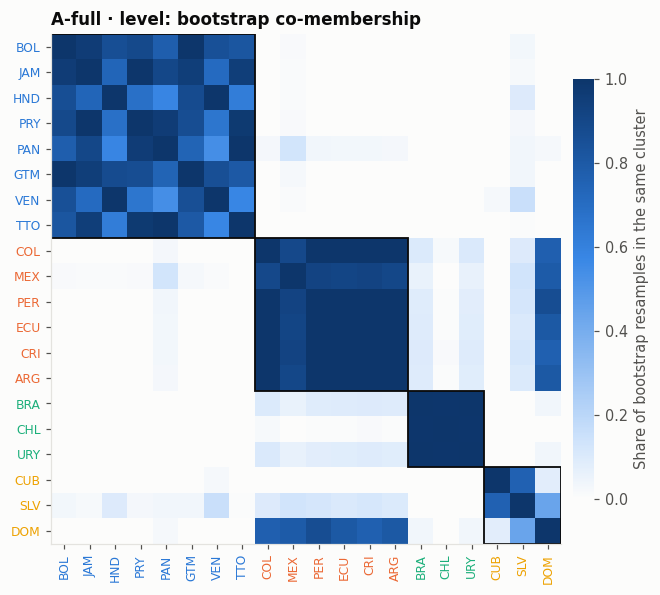

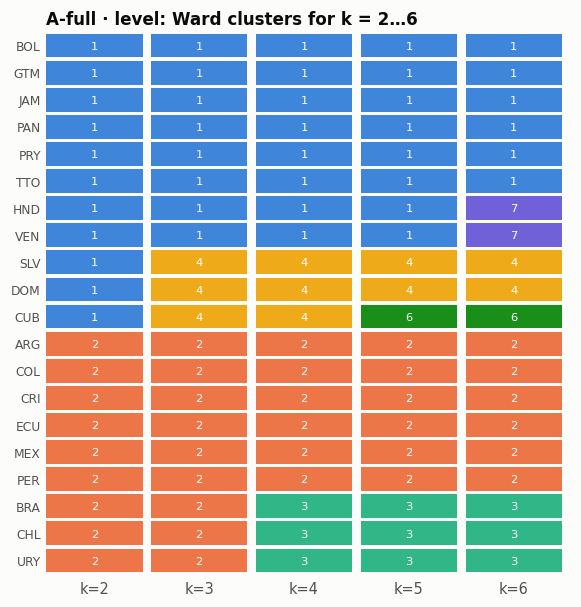


### A-pruned · level: k = 2 on 2 PCs
   silhouette_ward  silhouette_kmeans  ari_ward_vs_kmeans  min_cluster_size_ward    gap  gap_se  tibshirani_ok
k                                                                                                             
1              NaN                NaN                 NaN                    NaN  0.185   0.165          False
2            0.517              0.517               1.000                   10.0  0.372   0.171           True
3            0.528              0.528               1.000                    1.0  0.314   0.186           True
4            0.510              0.510               1.000                    1.0  0.428   0.195           True
5            0.470              0.453               0.782                    1.0  0.555   0.211           True
6            0.414              0.417               0.785                    1.0  0.472   0.221           True
cluster stability (mean Jaccard): {1: 0.95, 2: 0.95}


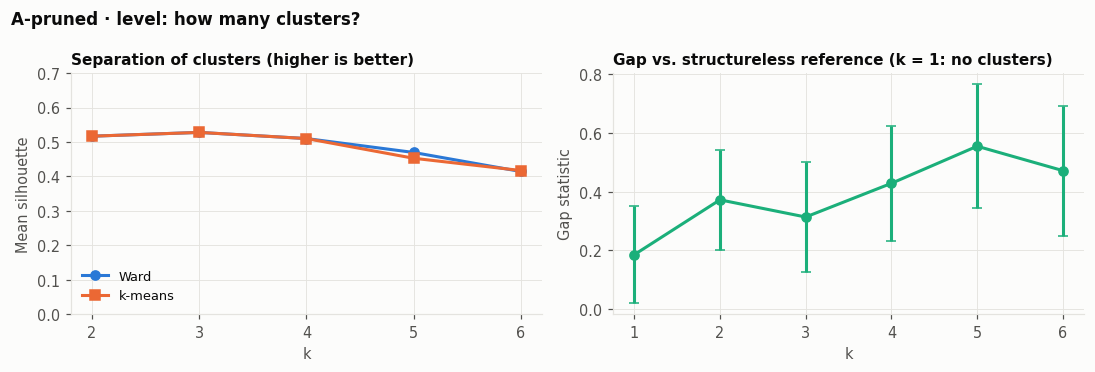

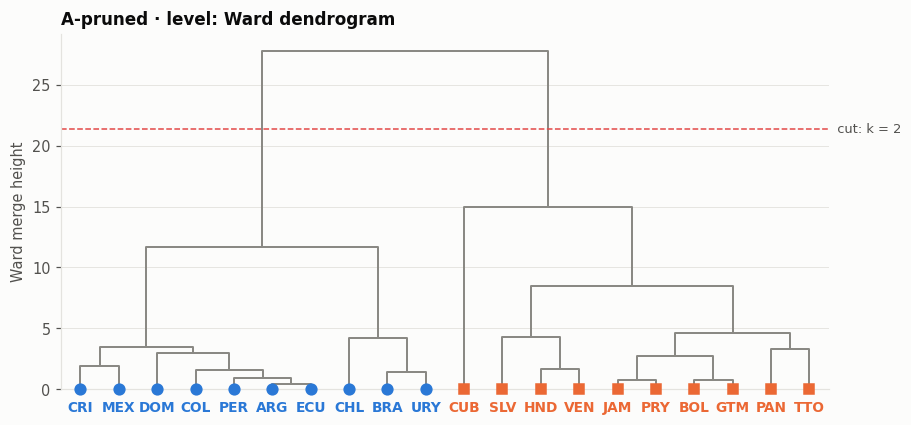

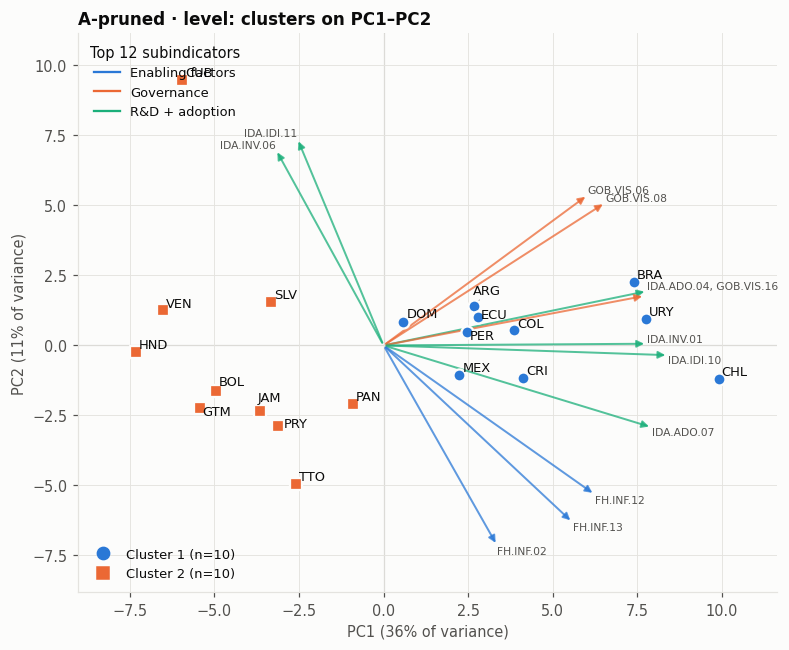

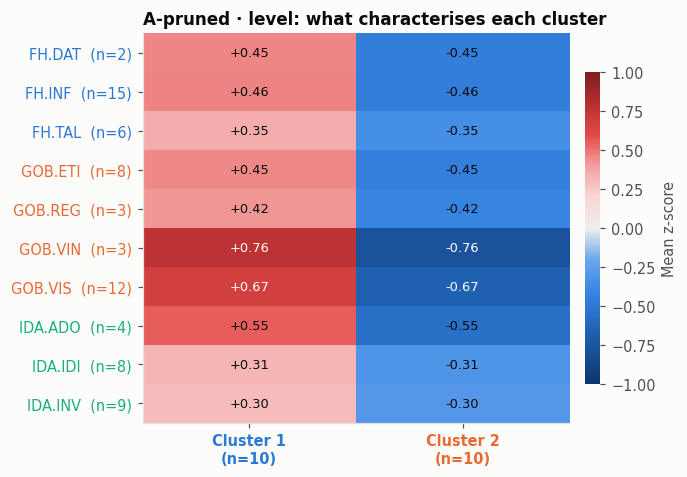

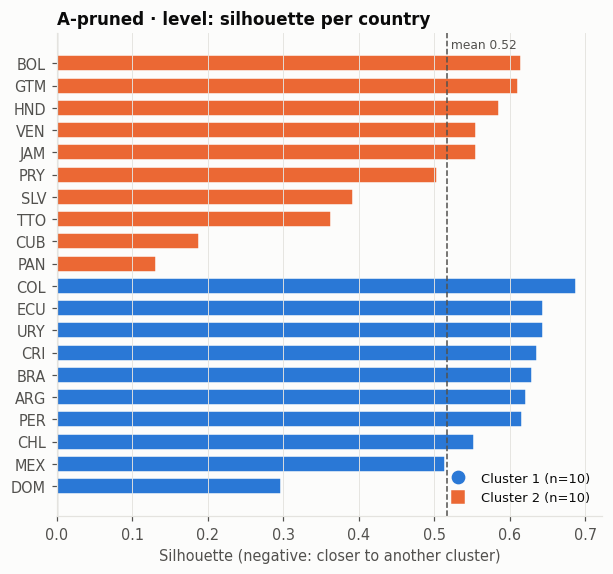

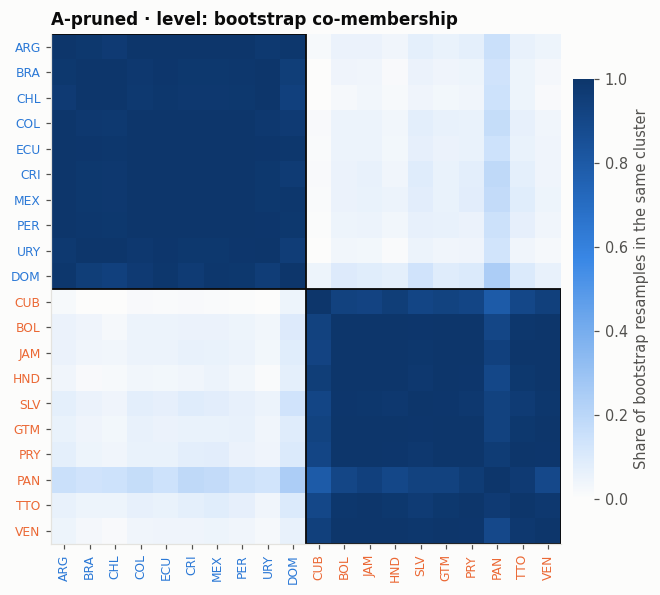

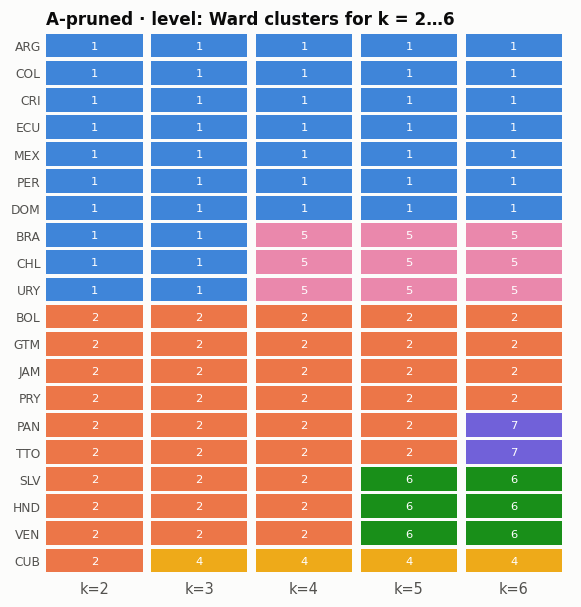


### I-full · level: k = 2 on 2 PCs
   silhouette_ward  silhouette_kmeans  ari_ward_vs_kmeans  min_cluster_size_ward    gap  gap_se  tibshirani_ok
k                                                                                                             
1              NaN                NaN                 NaN                    NaN  0.052   0.169          False
2            0.511              0.526               0.800                    9.0  0.281   0.169           True
3            0.493              0.517               0.806                    1.0  0.145   0.185           True
4            0.449              0.484               0.820                    1.0  0.246   0.198           True
5            0.385              0.425               0.598                    1.0  0.275   0.209           True
6            0.430              0.424               0.873                    1.0  0.354   0.220           True
cluster stability (mean Jaccard): {1: 0.91, 2: 0.9}


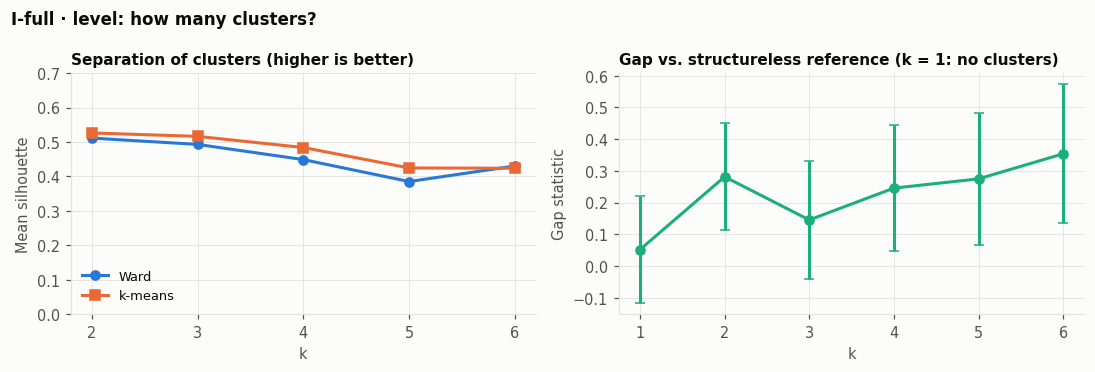

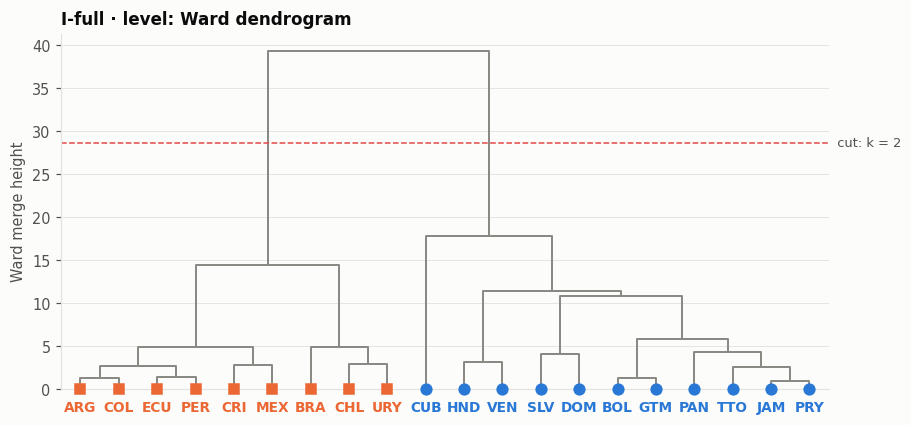

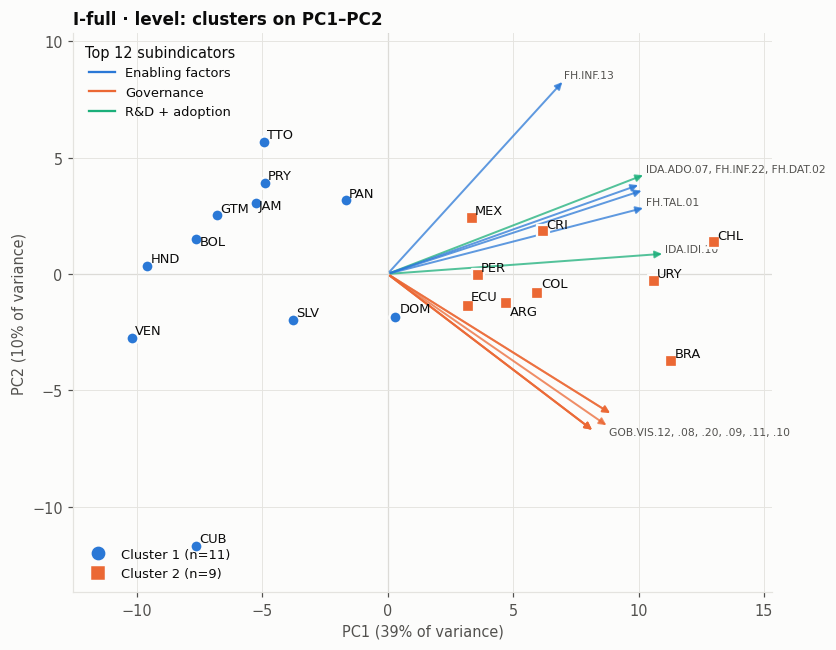

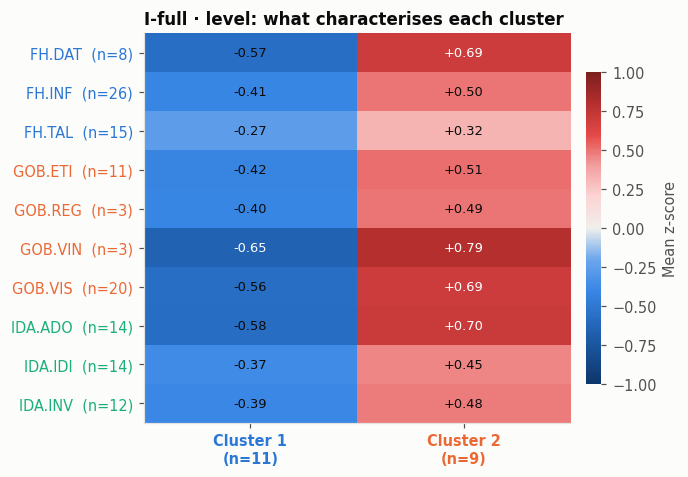

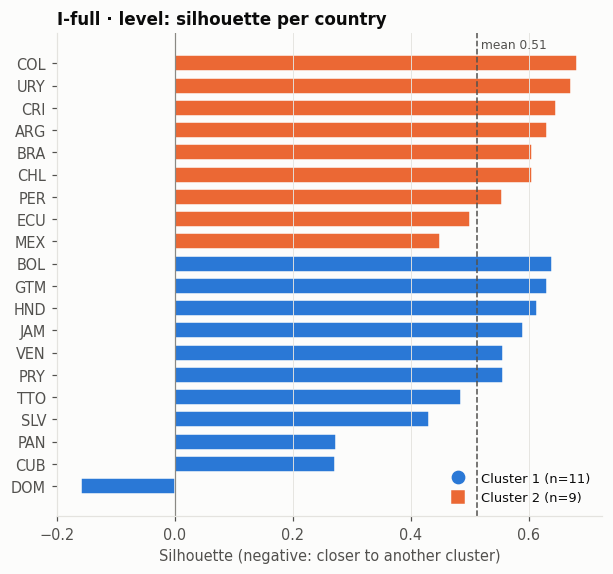

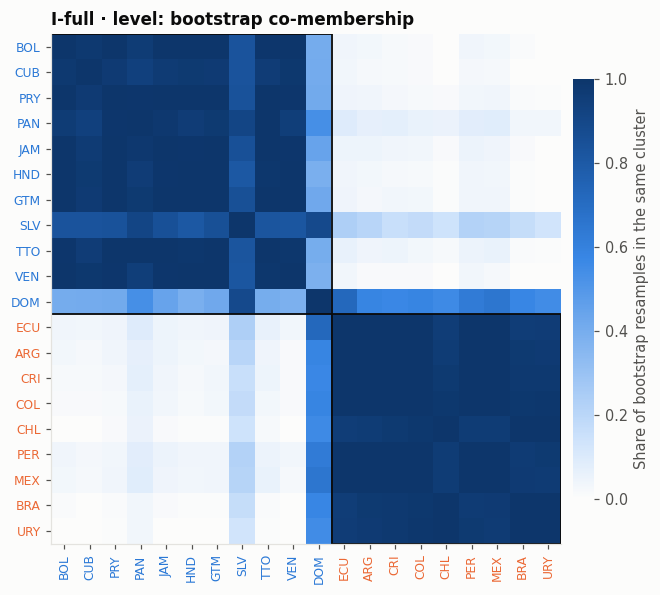

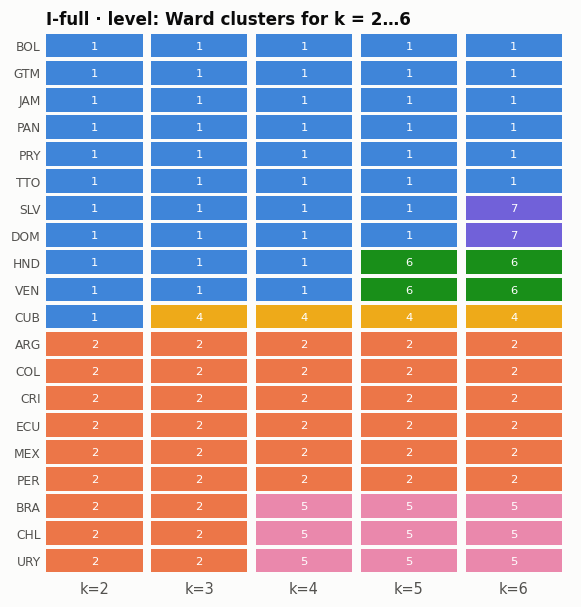


### I-pruned · level: k = 2 on 2 PCs
   silhouette_ward  silhouette_kmeans  ari_ward_vs_kmeans  min_cluster_size_ward    gap  gap_se  tibshirani_ok
k                                                                                                             
1              NaN                NaN                 NaN                    NaN  0.090   0.171           True
2            0.487              0.483               0.620                    9.0  0.215   0.168           True
3            0.460              0.465               0.345                    3.0  0.168   0.185           True
4            0.470              0.483               0.899                    1.0  0.354   0.198           True
5            0.452              0.443               0.815                    1.0  0.322   0.210           True
6            0.363              0.363               1.000                    1.0  0.348   0.220           True
cluster stability (mean Jaccard): {1: 0.87, 2: 0.86}


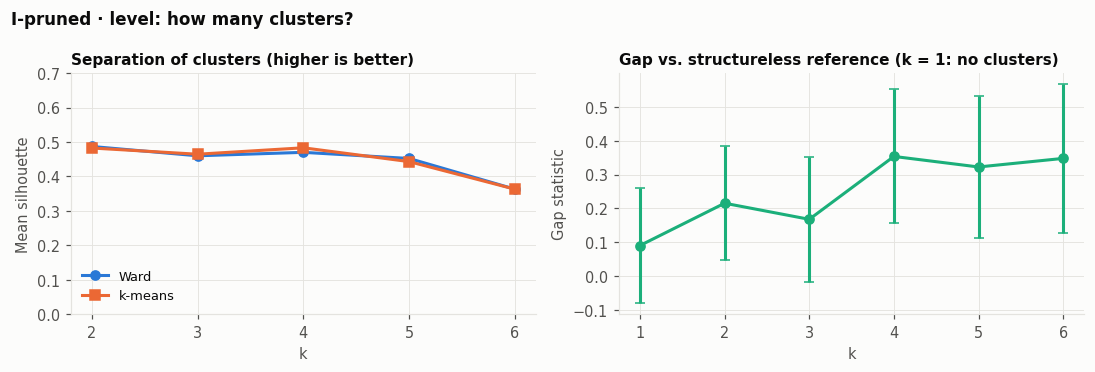

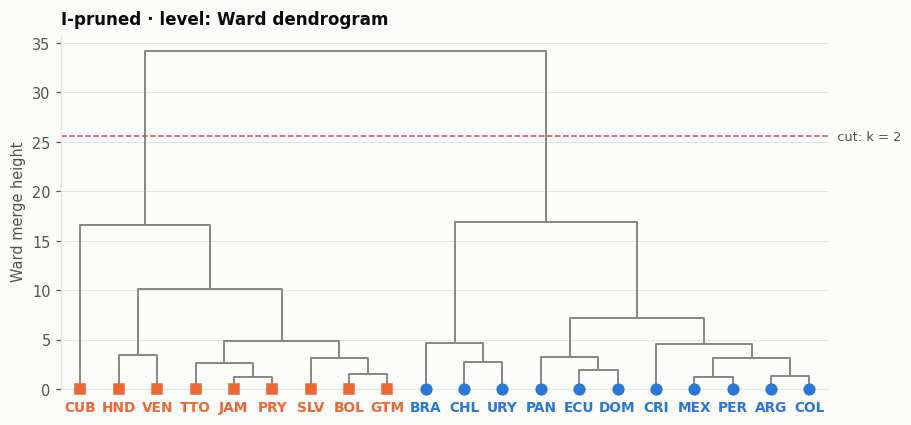

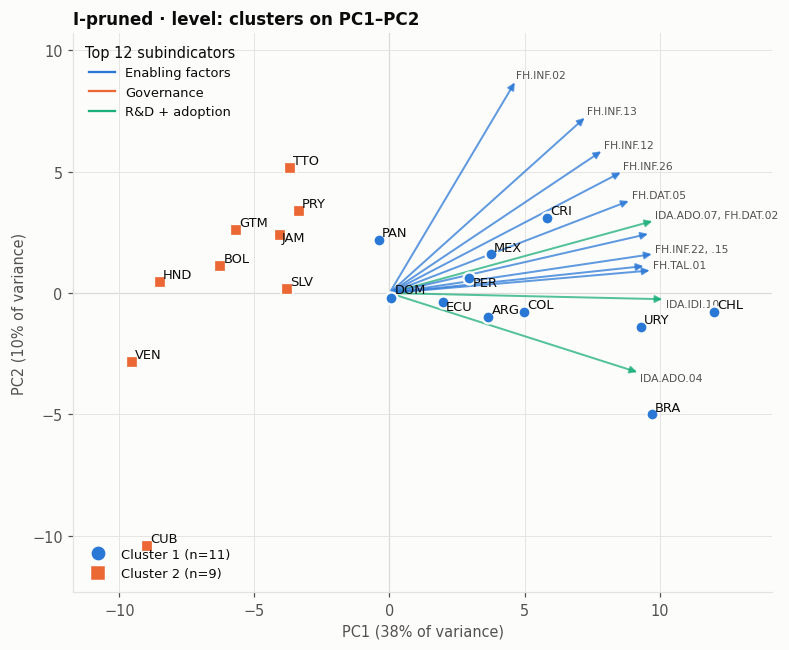

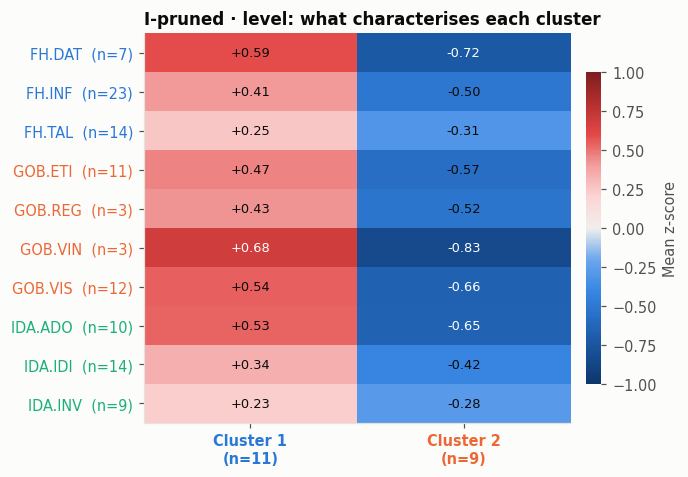

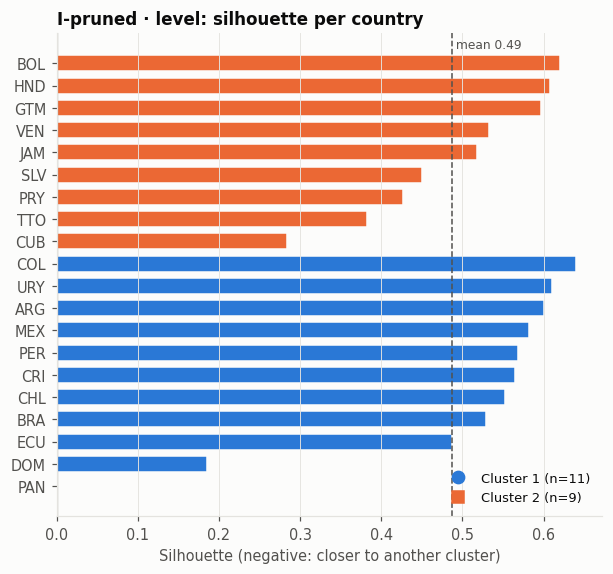

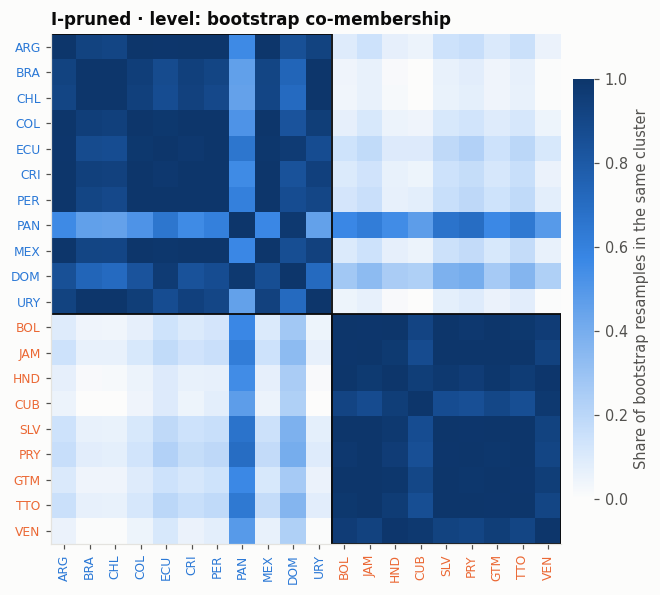

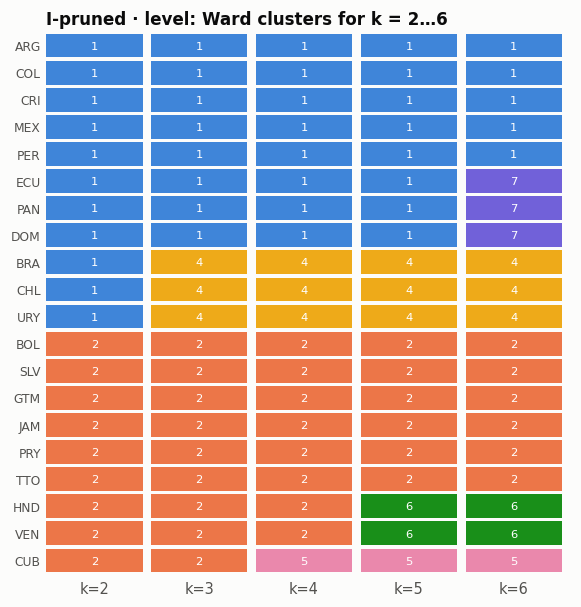

In [4]:
def show(r):
    t = r.tag
    print(f"\n### {r.config} · {r.mode}: k = {r.k} on {r.k_pc} PCs")
    print(r.evaluation.round(3).to_string())
    print("cluster stability (mean Jaccard):", r.jaccard.round(2).to_dict())
    fig = PL.k_diagnostics(r.evaluation, f"{r.config} · {r.mode}: how many clusters?"); PL.save(fig, f"04_{t}_k_diagnostics"); plt.show()
    fig = PL.dendro(r.linkage, r.X.index, r.k, r.ward, f"{r.config} · {r.mode}: Ward dendrogram"); PL.save(fig, f"04_{t}_dendrogram"); plt.show()
    fig = PL.biplot(r.pca, codebook, f"{r.config} · {r.mode}: clusters on PC1–PC2", labels=r.ward); PL.save(fig, f"04_{t}_cluster_map"); plt.show()
    fig = PL.cluster_profiles(r.Z, r.ward, codebook, f"{r.config} · {r.mode}: what characterises each cluster",
                              "Mean z-score" if r.mode == "level" else "Mean z-score relative to the country's own mean")
    PL.save(fig, f"04_{t}_cluster_profiles"); plt.show()
    fig = PL.silhouette_bars(r.silhouette, r.ward, f"{r.config} · {r.mode}: silhouette per country"); PL.save(fig, f"04_{t}_silhouette"); plt.show()
    fig = PL.comembership(r.comembership, r.ward, f"{r.config} · {r.mode}: bootstrap co-membership"); PL.save(fig, f"04_{t}_comembership"); plt.show()
    fig = PL.membership_across_k(r.membership_by_k, f"{r.config} · {r.mode}: Ward clusters for k = 2…6"); PL.save(fig, f"04_{t}_membership_by_k"); plt.show()

for cfg in PP.CONFIGS:
    show(runs[(cfg, "level")])

## Profile view (overall level removed)


### A-full · profile: k = 2 on 4 PCs
   silhouette_ward  silhouette_kmeans  ari_ward_vs_kmeans  min_cluster_size_ward    gap  gap_se  tibshirani_ok
k                                                                                                             
1              NaN                NaN                 NaN                    NaN  0.305   0.117           True
2            0.241              0.245               0.800                    9.0  0.099   0.121           True
3            0.248              0.250               0.487                    1.0  0.082   0.134           True
4            0.305              0.281               0.584                    1.0  0.177   0.146          False
5            0.322              0.331               0.746                    1.0  0.341   0.159           True
6            0.296              0.307               0.606                    1.0  0.335   0.149           True
cluster stability (mean Jaccard): {1: 0.7, 2: 0.62}


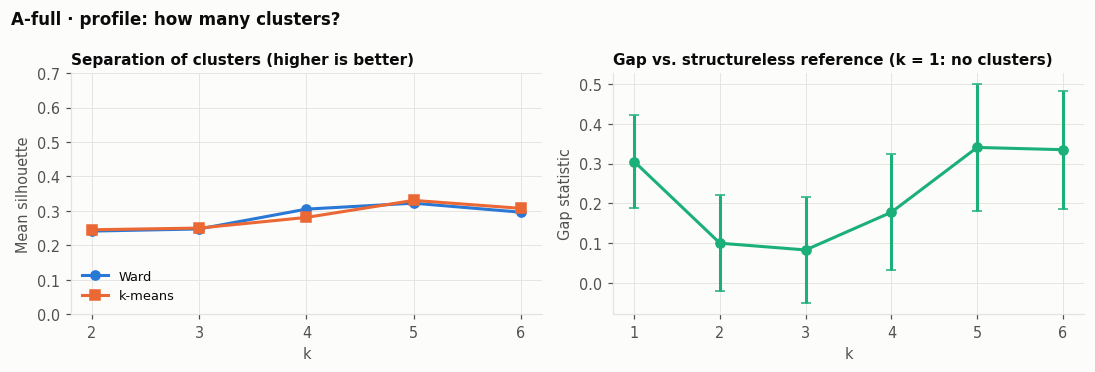

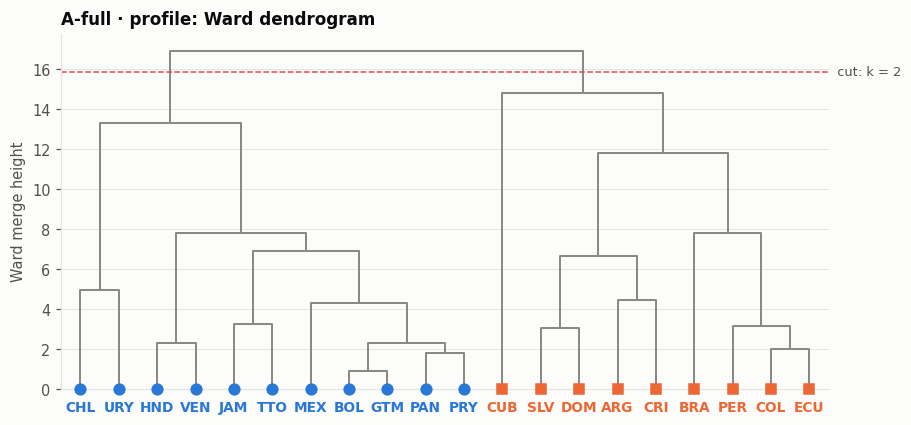

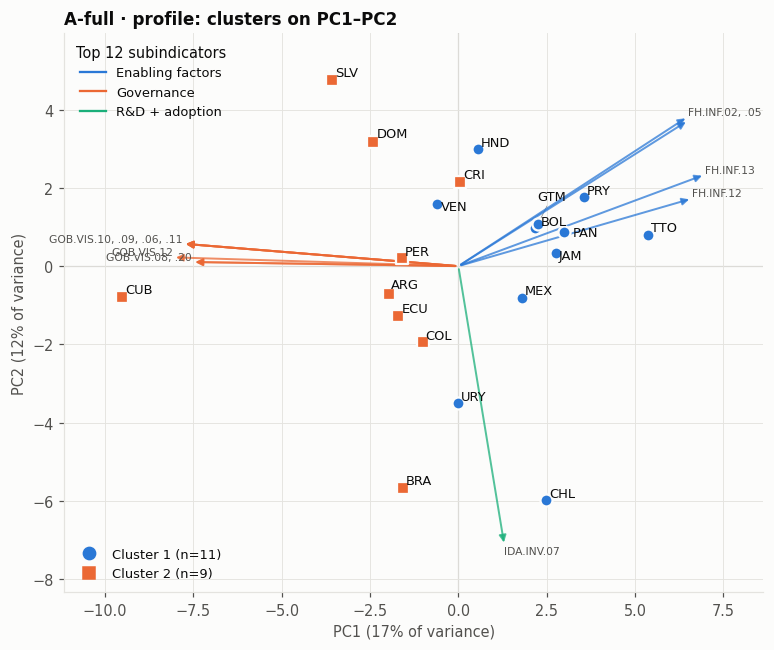

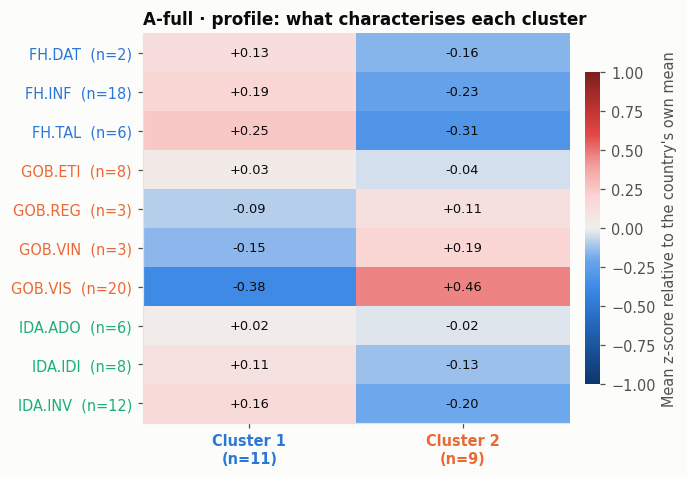

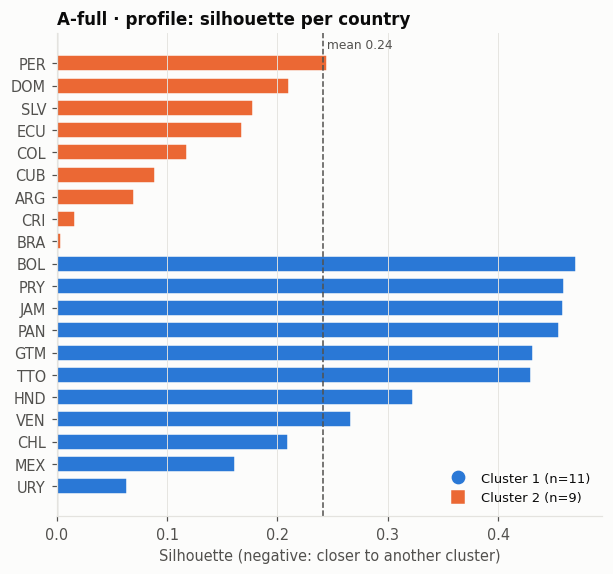

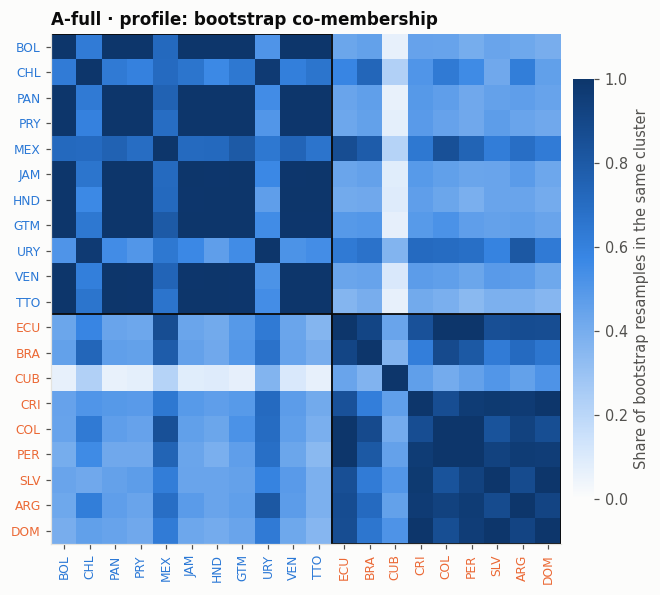

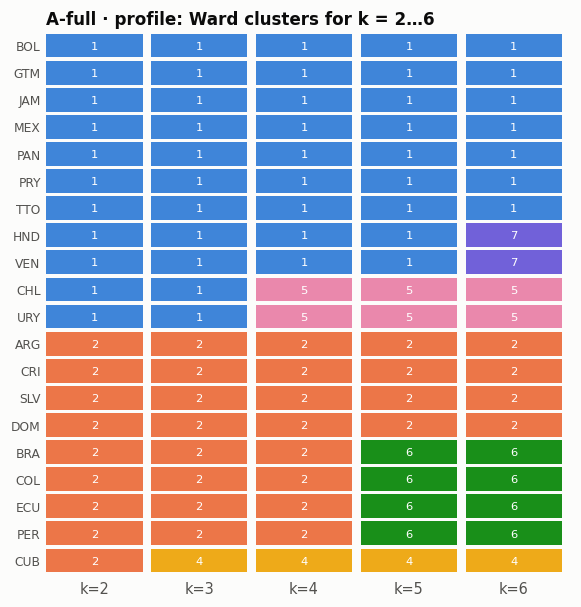


### A-pruned · profile: k = 2 on 3 PCs
   silhouette_ward  silhouette_kmeans  ari_ward_vs_kmeans  min_cluster_size_ward    gap  gap_se  tibshirani_ok
k                                                                                                             
1              NaN                NaN                 NaN                    NaN  0.351   0.126           True
2            0.530              0.530               1.000                    1.0  0.024   0.154           True
3            0.294              0.294               1.000                    1.0  0.099   0.137           True
4            0.299              0.315               0.295                    1.0  0.120   0.180           True
5            0.353              0.362               0.892                    1.0  0.213   0.176           True
6            0.347              0.350               0.879                    1.0  0.285   0.183           True
cluster stability (mean Jaccard): {1: 0.84, 2: 0.78}


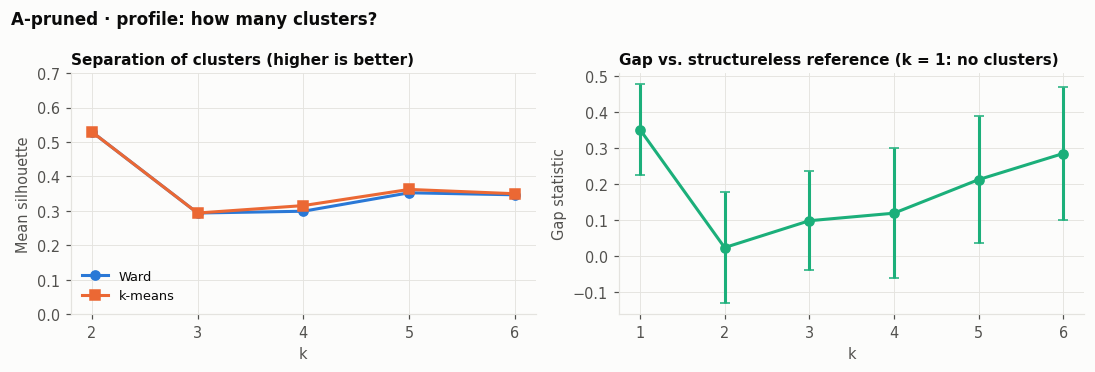

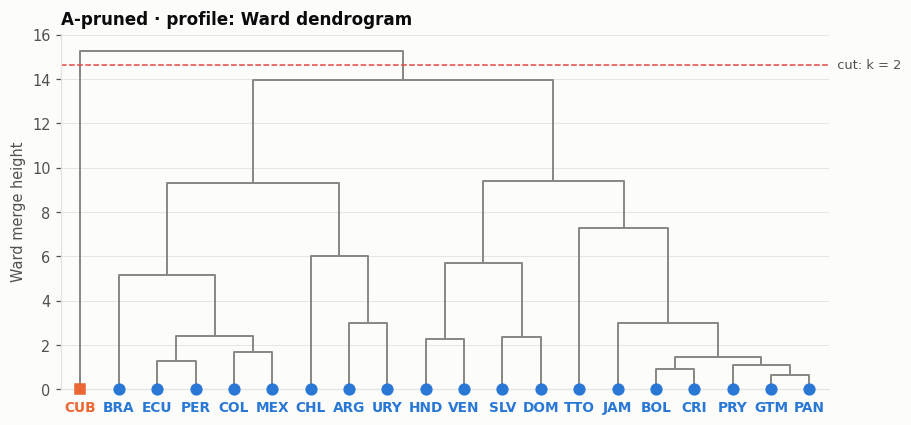

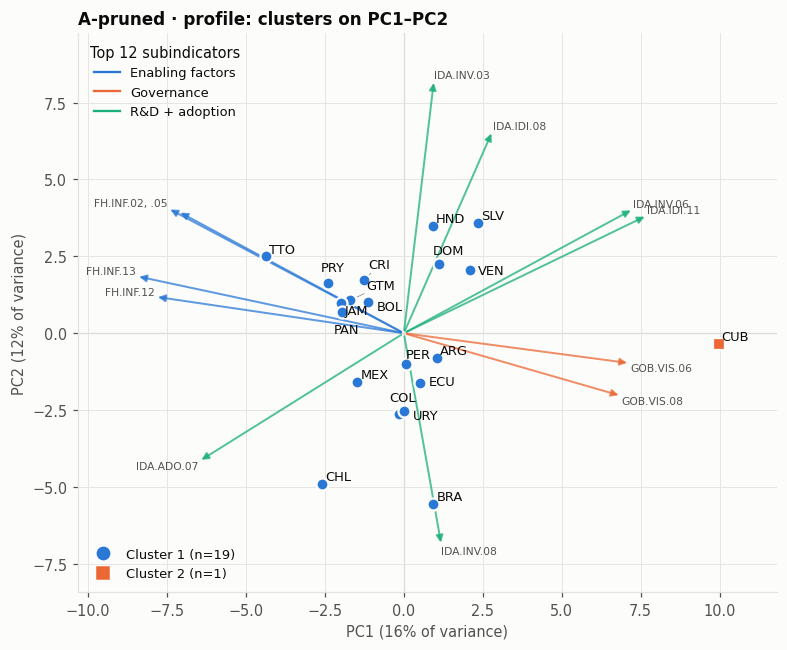

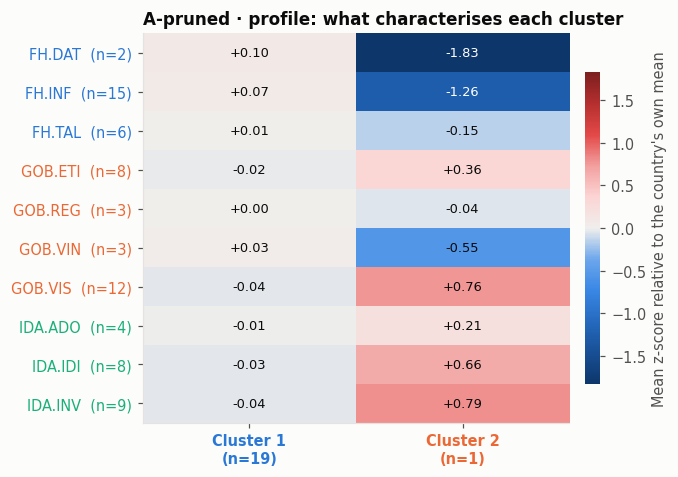

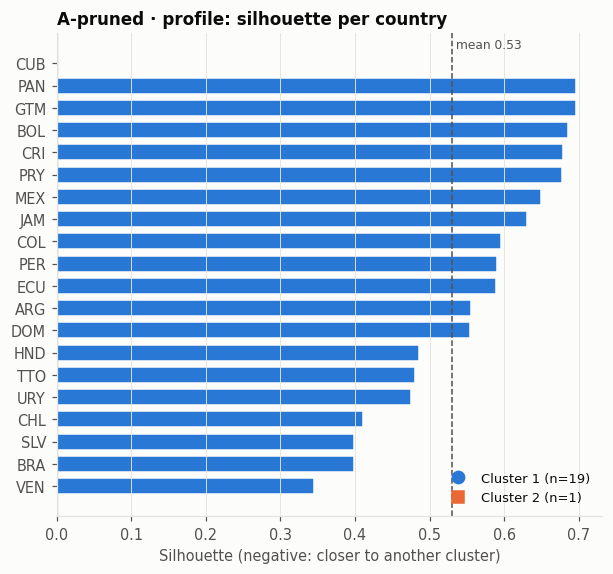

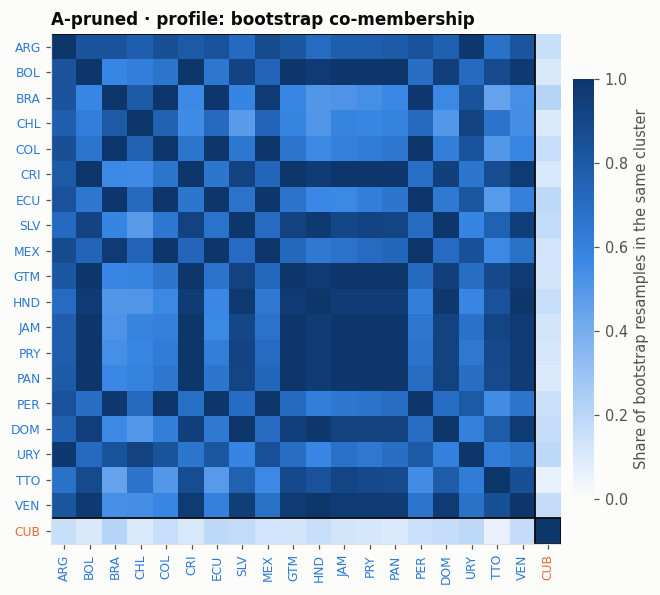

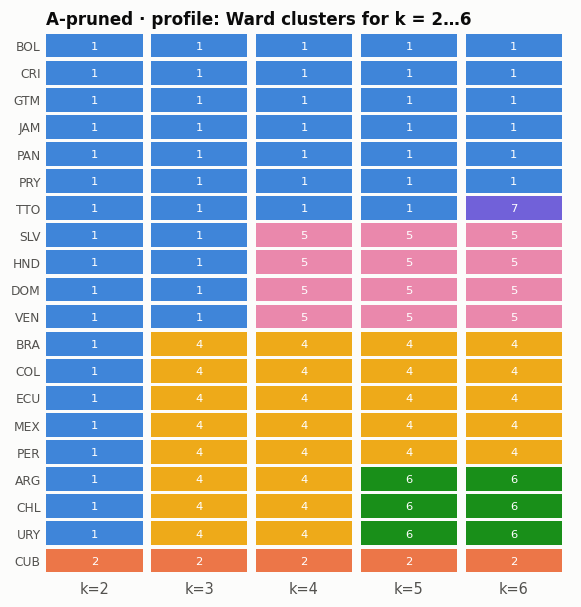


### I-full · profile: k = 2 on 4 PCs
   silhouette_ward  silhouette_kmeans  ari_ward_vs_kmeans  min_cluster_size_ward    gap  gap_se  tibshirani_ok
k                                                                                                             
1              NaN                NaN                 NaN                    NaN  0.253   0.113           True
2            0.205              0.203               0.800                    9.0  0.076   0.122           True
3            0.215              0.210               0.356                    1.0  0.033   0.136           True
4            0.246              0.261               0.523                    1.0  0.079   0.149           True
5            0.278              0.277               0.695                    1.0  0.142   0.158           True
6            0.247              0.289               0.387                    1.0  0.247   0.151           True
cluster stability (mean Jaccard): {1: 0.62, 2: 0.61}


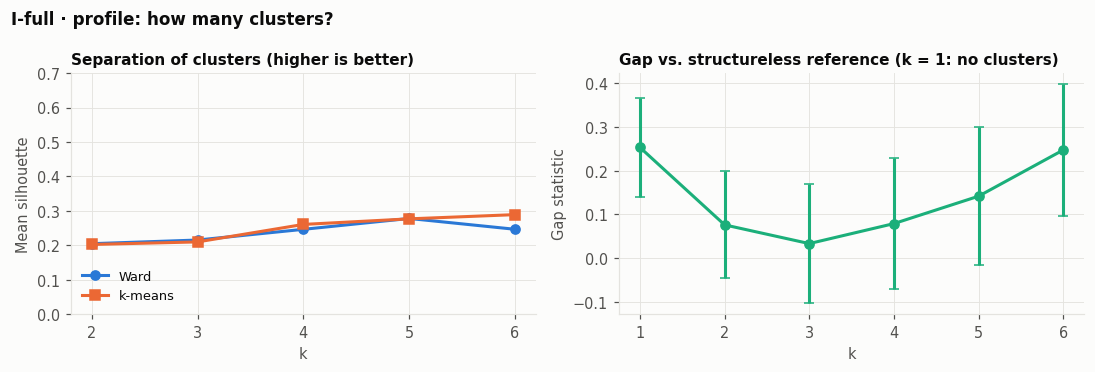

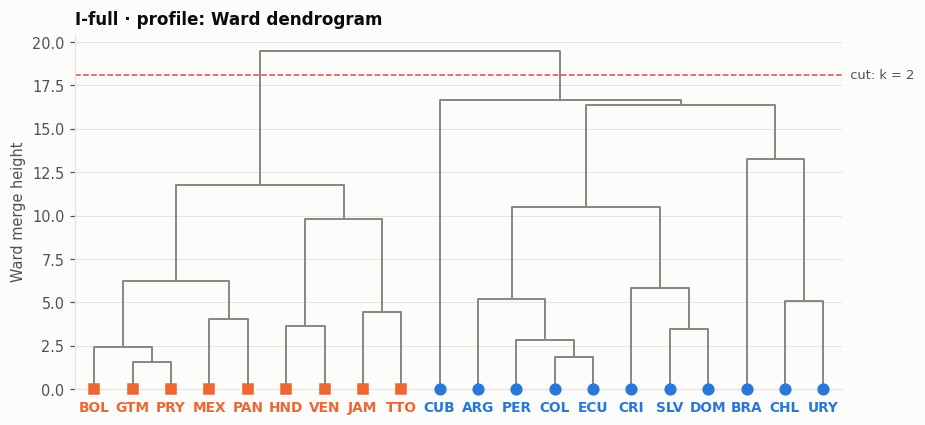

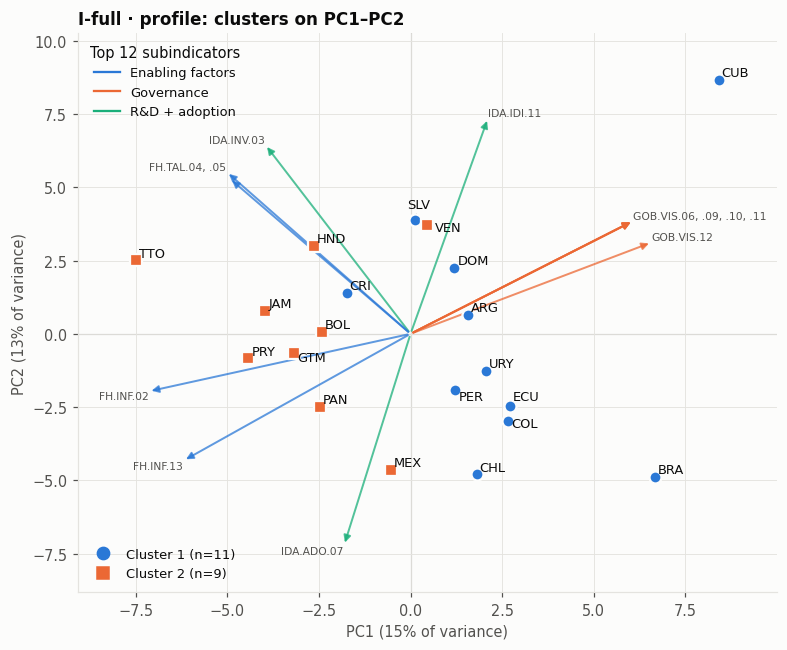

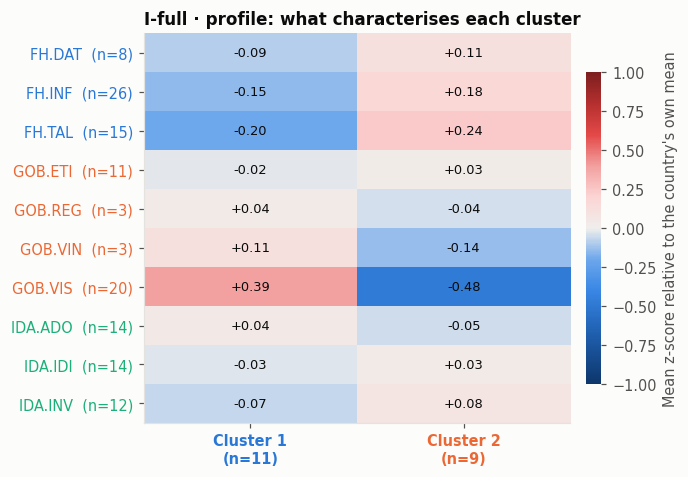

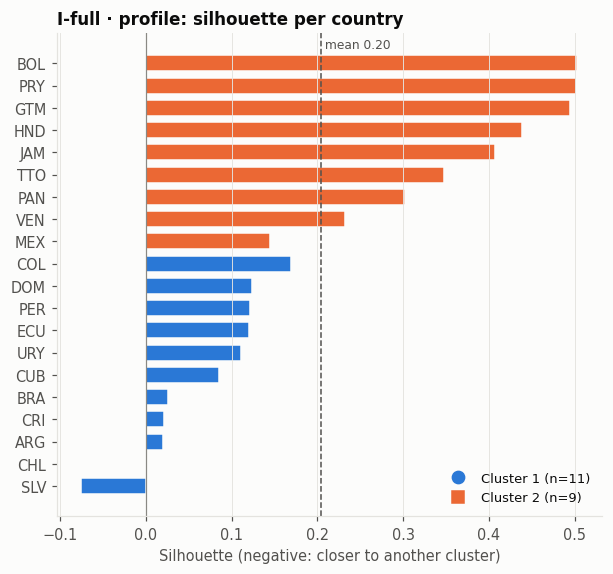

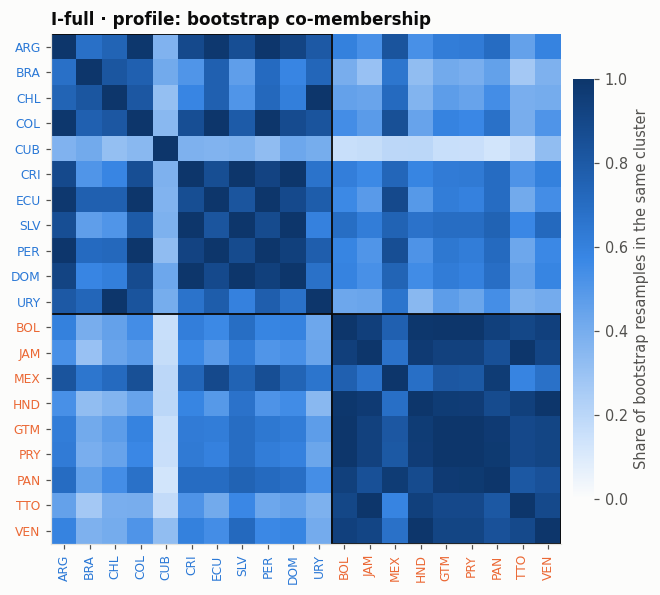

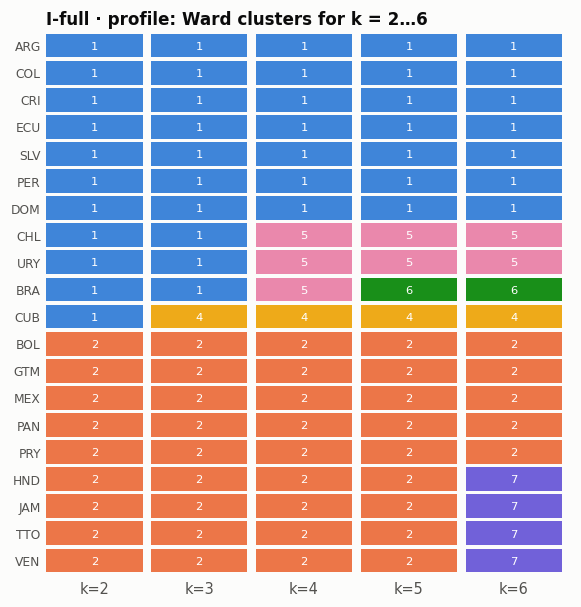


### I-pruned · profile: k = 2 on 4 PCs
   silhouette_ward  silhouette_kmeans  ari_ward_vs_kmeans  min_cluster_size_ward    gap  gap_se  tibshirani_ok
k                                                                                                             
1              NaN                NaN                 NaN                    NaN  0.287   0.112           True
2            0.194              0.194               1.000                    9.0  0.097   0.121           True
3            0.214              0.214               1.000                    1.0  0.086   0.137           True
4            0.223              0.214               0.354                    1.0  0.083   0.150           True
5            0.241              0.259               0.654                    1.0  0.108   0.158           True
6            0.260              0.294               0.892                    1.0  0.182   0.150           True
cluster stability (mean Jaccard): {1: 0.6, 2: 0.55}


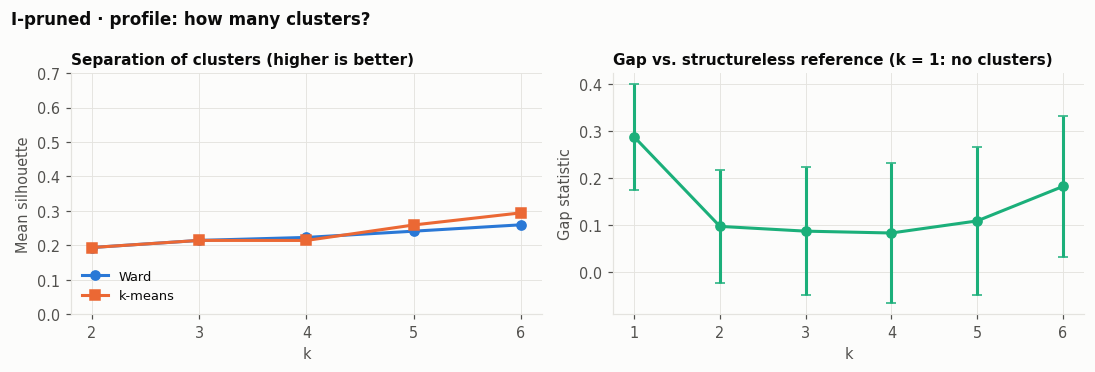

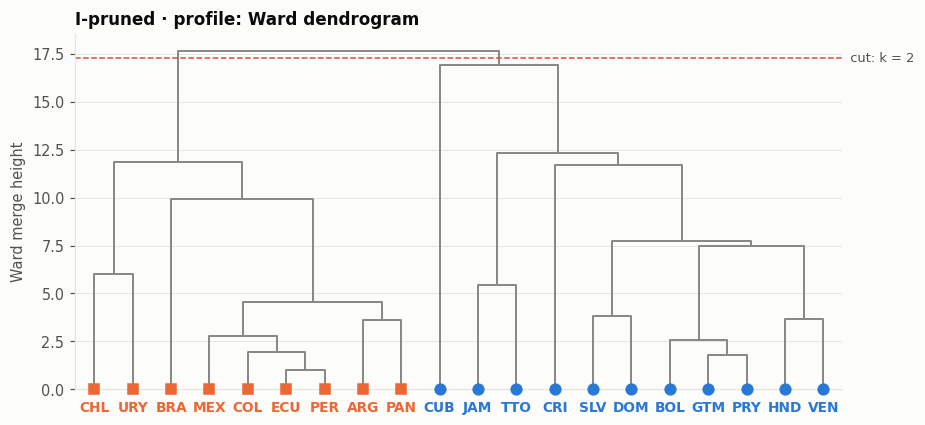

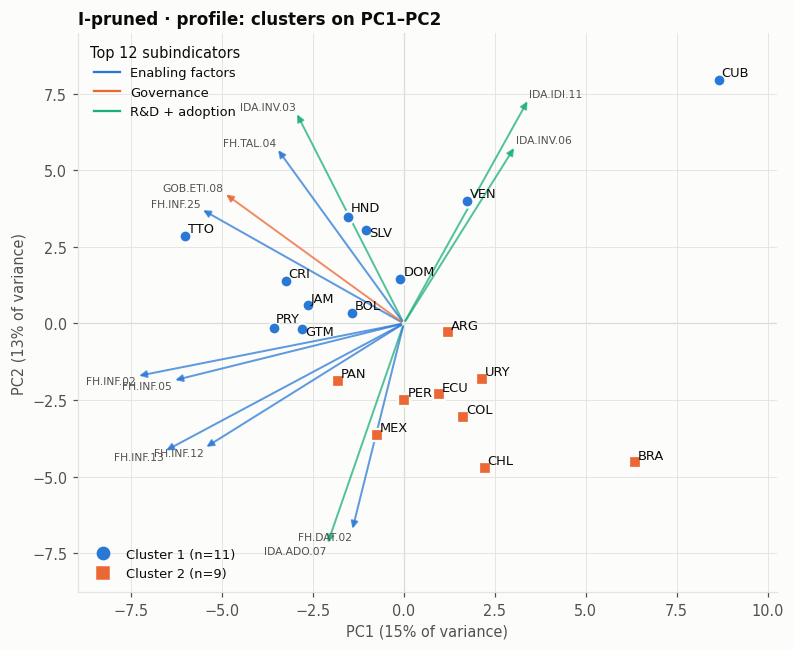

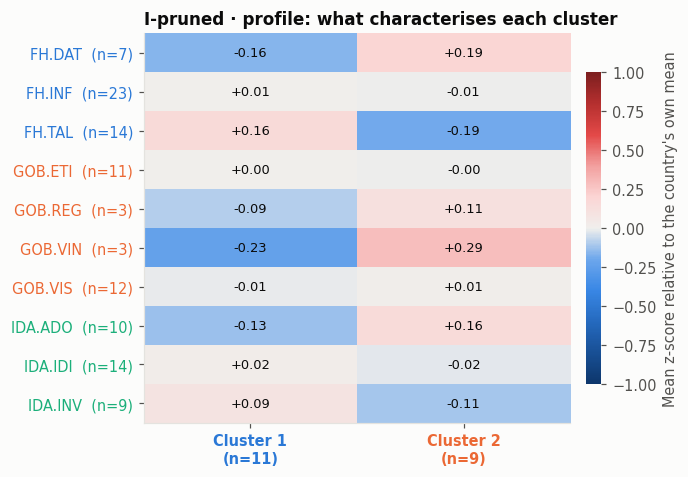

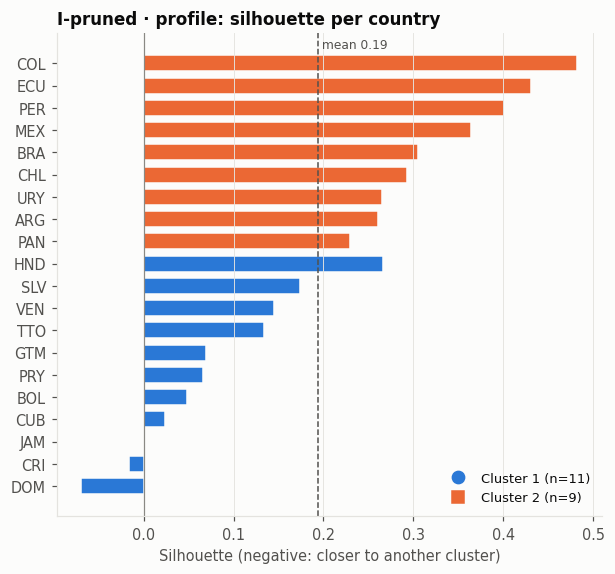

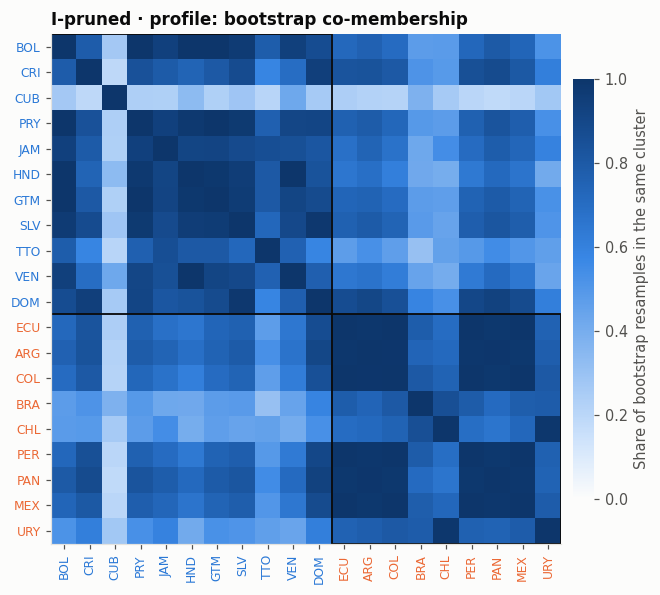

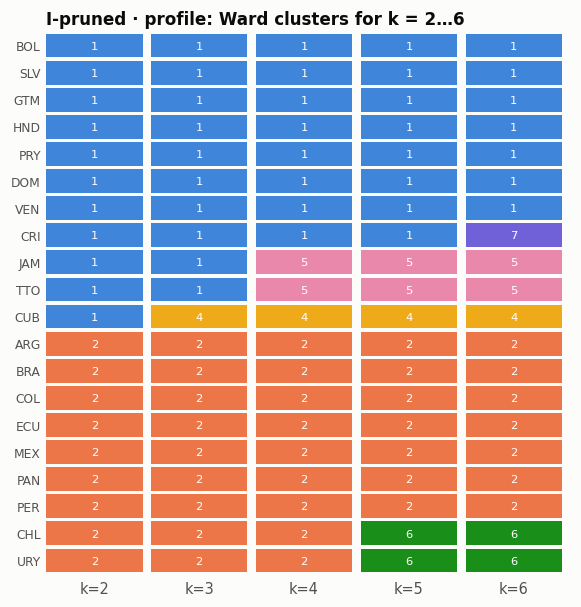

In [5]:
for cfg in PP.CONFIGS:
    show(runs[(cfg, "profile")])

## Reading the results

**Level view: a robust two-way split by overall level.**

* In all four configurations the countries divide into an upper half {ARG, BRA, CHL, COL, CRI, ECU, MEX, PER, URY}
  and a lower half {BOL, CUB, SLV, GTM, HND, JAM, PRY, TTO, VEN}. Mean cluster Jaccard is 0.83–0.95 and k-means agrees with Ward (ARI 0.62–1.00).
* **Borderline countries:** the Dominican Republic (negative silhouette in A-full and I-full; it joins the upper half in both pruned versions)
  and Panama (upper half in I-pruned).
* **A-full supports a finer reading with k = 4** (silhouette 0.53 against 0.50 at k = 2, a small margin; the gap rule prefers 2):
  * leaders **BRA, CHL, URY**, above average everywhere and especially in adoption (Jaccard 0.92);
  * an upper-middle group **ARG, COL, CRI, ECU, MEX, PER**, above average and fairly even;
  * a lower group **BOL, GTM, HND, JAM, PAN, PRY, TTO, VEN**, below average everywhere and weakest on strategy;
  * **CUB, SLV, DOM: strategy ahead of capabilities.** Above average on national strategy (GOB.VIS +0.53) and below on infrastructure (−0.76).
    It is the second split of the dendrogram and the least stable group (Jaccard 0.67, DOM often moves to the upper-middle group).

**Profile view: a gradient, not clusters.**

* The gap statistic prefers **k = 1** in every profile run, silhouettes are 0.19–0.24 and Jaccard is about 0.6.
* The k = 2 split still has a readable content, the same strategy-versus-capabilities contrast as PC2:
  relatively stronger on strategy {ARG, BRA, COL, CRI, CUB, ECU, SLV, PER, DOM} against relatively stronger on capabilities
  {BOL, CHL, GTM, HND, JAM, MEX, PAN, PRY, TTO, URY, VEN}. It is best read as a position along a continuum.
* In A-pruned, Cuba alone separates from everyone else (19/1).